# Evaluation of the RF protocol detection and classification models (LTE, DMR, P25, TETRA)

Evaluates everything trained on the synthetic spectrogram dataset (`01_create_dataset.ipynb`) on the four **frozen test sets**:

| Section | Experiment | Set |
|---|---|---|
| 2 | Detection: CFAR baseline vs YOLO26 | `test` |
| 3 | Protocol classification: feature classifier (gradient boosting) vs CNN | `test` |
| 4 | End-to-end pipelines, selection of the **best algorithm** | `test` |
| 5 | Robustness to unseen impairments | `test_robust` |
| 6 | Unknown signals (open set: NBFM, WFM, GSM) | `test_openset` |
| 7 | SNR outside the training range | `test_snr_stress` |
| 8 | Summary | |
| 9 | **Test**: the best algorithm on samples outside the dataset folder | `external_test/` |

**Before running**, train the models (from this folder; the outputs go to `runs/`):

```
python3 -m pip install -r requirements.txt
python3 baselines.py                                   # CFAR tuning + feature classifier       -> runs/baselines
python3 train_classifier.py                            # ResNet-18 on box crops                 -> runs/classifier
python3 train_detector.py                              # YOLO26-nano, 4 protocols               -> runs/detector
python3 train_detector.py --single-class --out runs/detector_1cls_yolo26s_6   # optional: boxes only, for the two-stage pipeline
```

Only what exists in `runs/` is evaluated. All scripts use `train` and `val` only; the test sets are touched here, once. The data is synthetic, so the numbers show how the models compare, not how they will perform on real signals.

Expect most classification errors between **DMR and P25**: both are 4800-baud 4-level FSK in a 12.5 kHz channel. A spectrogram only separates them by burst timing and fine shape. With the **IQ** stored in the dataset (`SPECTRUM_STORE_IQ=1`), the 4FSK deviation (648 vs 600 Hz) and the sync words are measured, and the `... + IQ refine` pipeline re-decides every box that the detector calls DMR or P25.

What changed with the second run (see `run_plan.md`):

- **IQ images:** `Detector` removes detections that are the mirror image of a stronger one (`spectrum_common.mirror_suppress`). The detector table also lists `YOLO (no mirror filter)` to show the effect, mostly on `test_robust`.
- **Distractors:** AM, CW and POCSAG signals are in every set and are not labels, so any detection on them counts as a false alarm. The ground truth used here contains only the four protocols.
- **Unknown signals:** besides the AUROC, the open-set section reports the ResNet at its calibrated operating point (`calibration.json`) and how often each detector fires on every unknown signal.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))                  # spectrum_common.py, baselines.py, train_*.py live next to this notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from scipy.optimize import linear_sum_assignment
from scipy.special import logsumexp, softmax
from sklearn.metrics import roc_auc_score, roc_curve
from tqdm.auto import tqdm

from spectrum_common import (DF, FAMILIES, FS, HOP, N_FFT, N_FRAMES, N_SAMPLES, PROJECT_DIR, SNR_LABELS, TEST_SETS, UNKNOWN_FAMILY_ID, SetReader,
                             box_center_hz, box_times_ms, cls_metrics, dequantize_db, find_dataset_root, gray_to_db, match_detections,
                             pick_device, save_json, snr_bin_labels, spectrogram_db)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

ROOT = find_dataset_root()                                                   # dataset/spectrum_rf_v0.3.0_pilot (or $SPECTRUM_ROOT)
YOLO_RUN = os.environ.get("YOLO_RUN", "detector")                                                  # runs/ subfolder of the 4-protocol YOLO detector
BASELINES_RUN = os.environ.get("BASELINES_RUN", "baselines")                                  # runs/ subfolder of cfar.json + feature_clf.joblib
CLASSIFIER_RUN = os.environ.get("CLASSIFIER_RUN", "classifier")                                  # runs/ subfolder of the CNN classifier
YOLO_1CLS_RUN = os.environ.get("YOLO_1CLS_RUN", "detector_1cls_yolo26s_6")                                    # which runs/ subfolder holds the one-class YOLO detector
RUNS = Path(os.environ.get("SPECTRUM_RUNS", PROJECT_DIR / "runs"))           # where the training scripts wrote their results
OUT = RUNS / "evaluation" / (YOLO_RUN if YOLO_RUN != "detector" else YOLO_1CLS_RUN)                                     # one summary.json per detector run
OUT.mkdir(parents=True, exist_ok=True)
MAX_SCENES = int(os.environ.get("EVAL_MAX_SCENES", "0")) or None            # e.g. 200 for a quick pass over every set
DEVICE = pick_device()
FAM_COLOR = ["white", "yellow", "cyan", "lime"]         # box colors on the viridis spectrograms, by family index
print(f"dataset: {ROOT}\nruns:    {RUNS}\ndevice:  {DEVICE}\nscenes per set: {MAX_SCENES or 'all'}")

/Users/tohid/Desktop/RF-Signal-Detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


dataset: /Users/tohid/Desktop/RF-Signal-Detection/dataset/spectrum_rf_v0.3.0_pilot
runs:    /Users/tohid/Desktop/RF-Signal-Detection/runs
device:  mps
scenes per set: all


## 1. Load the trained models and the frozen test sets

| Component | Produced by | File |
|---|---|---|
| CFAR detector (tuned on `val`) | `baselines.py` | `runs/<BASELINES_RUN>/cfar.json` (default parameters if missing) |
| Feature classifier (gradient boosting) | `baselines.py` | `runs/<BASELINES_RUN>/feature_clf.joblib` |
| CNN classifier (ResNet) | `train_classifier.py` | `runs/classifier/best.pt` |
| YOLO detector, 4 protocols | `train_detector.py` | `runs/detector/best.pt` |
| YOLO detector, one class (optional) | `train_detector.py --single-class --out runs/detector_1cls_yolo26s_6` | `runs/detector_1cls_yolo26s_6/best.pt` (`YOLO_1CLS_RUN`) |

Everything found is evaluated; missing optional parts are skipped. Models were selected on `val` only, so the four frozen test sets are used here for the first time. Set `EVAL_MAX_SCENES` to evaluate only the first N scenes of each set for a quick pass.

In [2]:
from baselines import CFARDetector, CFARParams, FeatureClassifier
from train_classifier import classify_boxes, energy_score, load_calibration, load_classifier

# ---- detectors: an object with detect(db) -> [dict(box=(x0, y0, x1, y1), score, ...)]
cfar_file = RUNS / BASELINES_RUN / "cfar.json"
DETECTORS = {"CFAR": CFARDetector(CFARParams(**json.loads(cfar_file.read_text())) if cfar_file.exists() else CFARParams())}
NO_MIRROR = "YOLO (no mirror filter)"                       # the same weights without the IQ-image filter: shows what the filter does
OP_CONF = {"YOLO": 0.25, "YOLO-1cls": 0.25, NO_MIRROR: 0.25}   # YOLO operating confidence; CFAR has its tuned threshold built in
for name, sub in (("YOLO", YOLO_RUN), ("YOLO-1cls", YOLO_1CLS_RUN)):
    if (RUNS / sub / "best.pt").exists():
        from train_detector import Detector
        DETECTORS[name] = Detector(RUNS / sub / "best.pt", conf=0.05)
        if name == "YOLO":
            DETECTORS[NO_MIRROR] = Detector(RUNS / sub / "best.pt", conf=0.05, mirror_filter=False)


def op_filter(dets, det_name):
    thr = OP_CONF.get(det_name)
    return dets if thr is None else [d for d in dets if d["score"] >= thr]


# ---- classifiers: fn(db, boxes, iq) -> (probabilities [n, 4], logits [n, 4] or None)
CLASSIFIERS, CLF_NEEDS_IQ = {}, {}
if (RUNS / BASELINES_RUN / "feature_clf.joblib").exists():
    _gb = FeatureClassifier.load(RUNS / BASELINES_RUN / "feature_clf.joblib")
    CLASSIFIERS["GBM"] = lambda db, boxes, iq=None: (_gb.predict_proba(db, boxes, iq), None)
    CLF_NEEDS_IQ["GBM"] = _gb.use_iq
if (RUNS / CLASSIFIER_RUN / "best.pt").exists():
    _rn, _ck = load_classifier(RUNS / CLASSIFIER_RUN / "best.pt", DEVICE)

    def _resnet(db, boxes, iq=None):
        logits = classify_boxes(_rn, db, boxes, DEVICE)
        return softmax(logits, axis=1), logits

    CLASSIFIERS["ResNet"] = _resnet
    CLF_NEEDS_IQ["ResNet"] = False
    print(f"CNN: {_ck['arch']}, best epoch {_ck['epoch']}, val macro-F1 {_ck['val_macro_f1']:.3f}")
if not CLASSIFIERS:
    raise RuntimeError("no classifier found: run baselines.py and train_classifier.py first")

# ---- pipelines: (detector, classifier); classifier None = the detector predicts the family itself (single-stage)
# "... + IQ refine": single-stage detector, then every box called DMR or P25 is re-decided by the GBM from the stored IQ (4FSK deviation, sync words)
HAS_IQ = SetReader(ROOT, "test", 1).iq(0) is not None
REFINER = _gb if "GBM" in CLASSIFIERS and any(n.startswith("nb_") for n in _gb.names) else None
if REFINER is None:
    print("IQ refine unavailable:", "the dataset has no IQ (SPECTRUM_STORE_IQ=1)" if not HAS_IQ else "train baselines.py on a dataset with IQ")
REFINE_PIPES = set()
PIPELINES = {}
for d in DETECTORS:
    if d == NO_MIRROR:
        continue                                                # only compared as a detector
    for c in CLASSIFIERS:
        PIPELINES[f"{d} + {c}"] = (d, c)
    if hasattr(DETECTORS[d], "single_class") and not DETECTORS[d].single_class:
        PIPELINES[f"{d} (single-stage)"] = (d, None)
        if REFINER is not None and HAS_IQ:
            PIPELINES[f"{d} (single-stage) + IQ refine"] = (d, None)
            REFINE_PIPES.add(f"{d} (single-stage) + IQ refine")
print("detectors:  ", list(DETECTORS))
print("classifiers:", list(CLASSIFIERS))
print("pipelines:  ", list(PIPELINES))

CNN: resnet18, best epoch 26, val macro-F1 0.985
detectors:   ['CFAR', 'YOLO', 'YOLO (no mirror filter)']
classifiers: ['GBM', 'ResNet']
pipelines:   ['CFAR + GBM', 'CFAR + ResNet', 'YOLO + GBM', 'YOLO + ResNet', 'YOLO (single-stage)']


## 2. Detection (E2)

Every detector is run on the frozen `test` set and its boxes are matched one-to-one to the true boxes at IoU 0.5. Reported: precision, recall and F1, probability of detection vs SNR, recall per burst type (continuous down to 2 ms bursts), a precision-recall curve over all scores and the localization error (center frequency, bandwidth, start and end time) of the matched boxes. CFAR uses the parameters tuned on `val` by `baselines.py`; YOLO is evaluated at the confidence set in `OP_CONF`.


Before the test results, the **YOLO training curves** are plotted from the Ultralytics log `results.csv` of each detector run (`runs/detector/train/results.csv`, `runs/detector_1cls_yolo26s_6/train/results.csv`): train / val loss and val precision, recall, mAP per epoch. These are validation curves from training, not test results; runs without a log are skipped.

In [3]:
READERS = {s: SetReader(ROOT, s, MAX_SCENES) for s in TEST_SETS}
display(pd.DataFrame({s: dict(scenes=len(r), boxes=len(r.signals), groups=r.scenes.group_id.nunique()) for s, r in READERS.items()}).T)

DET_CACHE = {}


def run_detector(set_name, det_name, chunk=64):
    """Detections of every scene of a set: list (per scene) of dicts with box (x0, y0, x1, y1), score and, for YOLO, cls."""
    key = (set_name, det_name)
    if key not in DET_CACHE:
        rd, det, out = READERS[set_name], DETECTORS[det_name], []
        for s in tqdm(range(0, len(rd), chunk), desc=f"{det_name} on {set_name}"):
            dbs = [rd.spec_db(i) for i in range(s, min(s + chunk, len(rd)))]
            out += det.detect_batch(dbs) if hasattr(det, "detect_batch") else [det.detect(d) for d in dbs]
        DET_CACHE[key] = out
    return DET_CACHE[key]


,scenes,boxes,groups
test,1500,3142,30
test_robust,1000,2190,20
test_openset,1000,2151,20
test_snr_stress,1000,2434,20


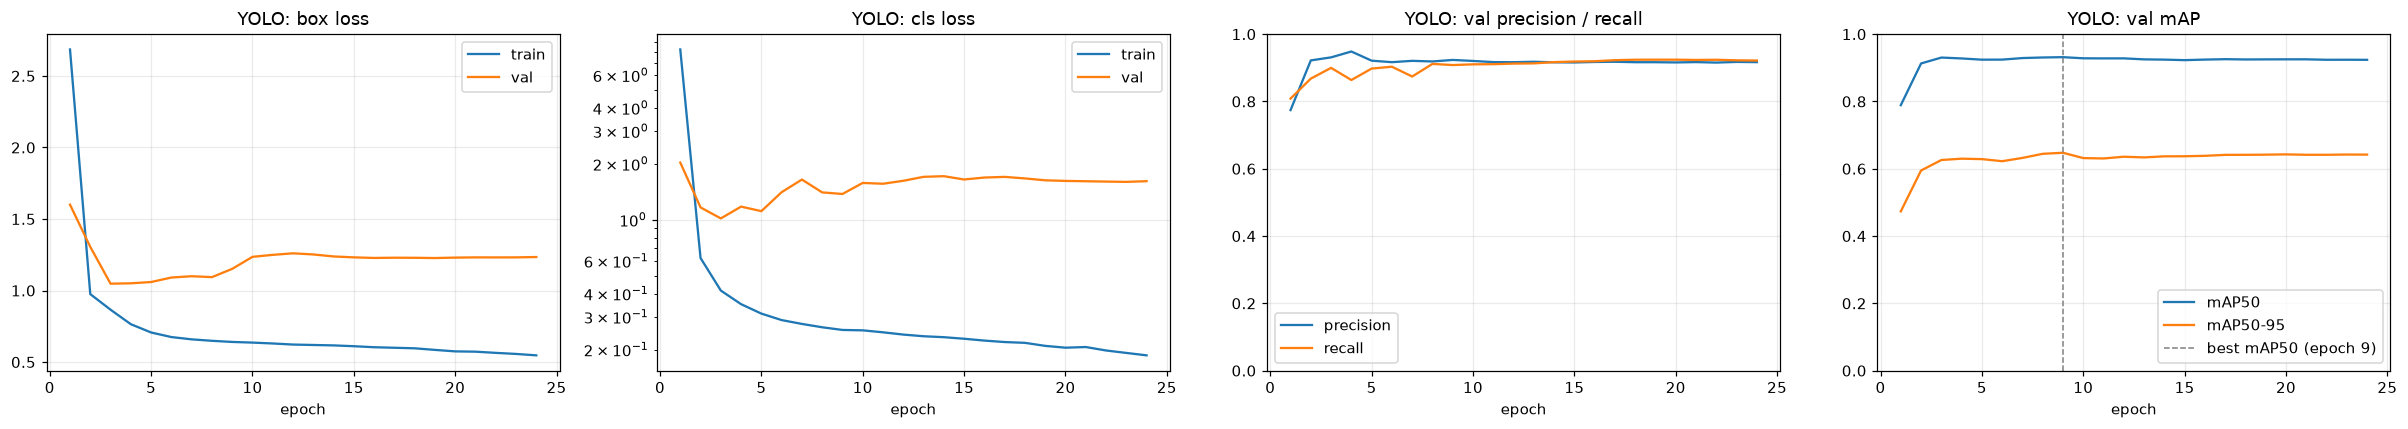

YOLO: 24 epochs logged, best val mAP50 0.932, mAP50-95 0.648 (epoch 9); last epoch mAP50 0.924
YOLO-1cls: no training log at /Users/tohid/Desktop/RF-Signal-Detection/runs/detector_1cls_yolo26s_6/train/results.csv


In [4]:
# ---- YOLO training curves from the Ultralytics log (train / val only: these are not test results)
CURVE_COLS = [("train/box_loss", "val/box_loss", "box loss"), ("train/cls_loss", "val/cls_loss", "cls loss")]
for name, sub in (("YOLO", YOLO_RUN), ("YOLO-1cls", YOLO_1CLS_RUN)):
    log_file = RUNS / sub / "train" / "results.csv"
    if not log_file.exists():
        print(f"{name}: no training log at {log_file}")
        continue
    hist = pd.read_csv(log_file)
    hist.columns = hist.columns.str.strip()                                  # Ultralytics pads some column names with spaces
    fig, ax = plt.subplots(1, 4, figsize=(22, 4))
    for a, (tr, va, title) in zip(ax[:2], CURVE_COLS):
        a.plot(hist["epoch"], hist[tr], label="train")
        a.plot(hist["epoch"], hist[va], label="val")
        a.set(title=f"{name}: {title}", xlabel="epoch")
        if title == "cls loss":
            a.set_yscale("log")                                              # val cls loss can spike by an order of magnitude
        a.legend()
    for col, label in (("metrics/precision(B)", "precision"), ("metrics/recall(B)", "recall")):
        ax[2].plot(hist["epoch"], hist[col], label=label)
    ax[2].set(title=f"{name}: val precision / recall", xlabel="epoch", ylim=(0, 1))
    ax[2].legend()
    for col, label in (("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95")):
        ax[3].plot(hist["epoch"], hist[col], label=label)
    best = hist["metrics/mAP50(B)"].idxmax()
    ax[3].axvline(hist["epoch"][best], color="gray", ls="--", lw=1, label=f"best mAP50 (epoch {int(hist['epoch'][best])})")
    ax[3].set(title=f"{name}: val mAP", xlabel="epoch", ylim=(0, 1))
    ax[3].legend()
    plt.tight_layout()
    plt.show()
    print(f"{name}: {len(hist)} epochs logged, best val mAP50 {hist['metrics/mAP50(B)'].max():.3f}, "
          f"mAP50-95 {hist['metrics/mAP50-95(B)'].max():.3f} (epoch {int(hist['epoch'][best])}); last epoch mAP50 {hist['metrics/mAP50(B)'].iloc[-1]:.3f}")

In [5]:
BOX_COLS = ["box_x0", "box_y0", "box_x1", "box_y1"]


def gt_arrays(rd, i):
    g = rd.boxes(i)
    g = g[g.family_id <= len(FAMILIES)].reset_index(drop=True)     # distractors (AM, CW, POCSAG) and held-out signals are not targets: a detection on them is a false alarm
    return g, g[BOX_COLS].to_numpy()


def add_snr_bin(df, col="snr"):
    df["snr_bin"] = pd.Categorical(snr_bin_labels(df[col]).astype(object), categories=SNR_LABELS, ordered=True)
    return df


def eval_detection(set_name, det_name, thr=0.5, apply_op=True):
    """Match detections to the true boxes (IoU >= thr, one-to-one). Returns (one row per true box, one row per detection)."""
    rd, gt_rows, pr_rows = READERS[set_name], [], []
    for i, dets in enumerate(run_detector(set_name, det_name)):
        if apply_op:
            dets = op_filter(dets, det_name)
        g, gb = gt_arrays(rd, i)
        m = match_detections([d["box"] for d in dets], [d["score"] for d in dets], gb, thr)
        hit = {int(k) for k in m[m >= 0]}
        for k, r in enumerate(g.itertuples()):
            gt_rows.append(dict(scene=i, snr=r.snr_db, burst=r.burst_type, family_id=r.family_id, detected=k in hit))
        for p, d in enumerate(dets):
            row = dict(scene=i, score=d["score"], tp=bool(m[p] >= 0))
            if m[p] >= 0:
                gbox = gb[m[p]]
                (pt0, pt1), (gt0, gt1) = box_times_ms(d["box"]), box_times_ms(gbox)
                row.update(df_hz=box_center_hz(d["box"]) - box_center_hz(gbox), bw_ratio=(d["box"][2] - d["box"][0] + 1) / (gbox[2] - gbox[0] + 1),
                           dt0_ms=pt0 - gt0, dt1_ms=pt1 - gt1)
            pr_rows.append(row)
    return pd.DataFrame(gt_rows), pd.DataFrame(pr_rows, columns=["scene", "score", "tp", "df_hz", "bw_ratio", "dt0_ms", "dt1_ms"])   # fixed columns: a model with no detections still works


def det_summary(gt, pr):
    tp = int(pr.tp.sum()) if len(pr) else 0
    fp, fn = len(pr) - tp, len(gt) - int(gt.detected.sum())
    return dict(precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1), n_pred=len(pr), n_gt=len(gt))


def pr_curve(set_name, det_name):
    """Greedy matching by descending score is consistent for every score threshold, so one matching gives the whole curve."""
    gt, pr = eval_detection(set_name, det_name, apply_op=False)
    pr = pr.sort_values("score", ascending=False)
    tp = pr.tp.cumsum().to_numpy()
    return tp / np.arange(1, len(pr) + 1), tp / len(gt)


DET_RESULTS = {d: eval_detection("test", d) for d in DETECTORS}
DET_TABLE = pd.DataFrame({d: det_summary(*res) for d, res in DET_RESULTS.items()}).T
print("Detection on the frozen test set (IoU 0.5, YOLO at its operating confidence):")
display(DET_TABLE)

CFAR on test:   0%|                                                                                                                                                                       | 0/24 [00:00<?, ?it/s]

CFAR on test:   4%|██████▋                                                                                                                                                        | 1/24 [00:02<00:53,  2.34s/it]

CFAR on test:   8%|█████████████▎                                                                                                                                                 | 2/24 [00:04<00:50,  2.29s/it]

CFAR on test:  12%|███████████████████▉                                                                                                                                           | 3/24 [00:06<00:47,  2.27s/it]

CFAR on test:  17%|██████████████████████████▌                                                                                                                                    | 4/24 [00:09<00:46,  2.30s/it]

CFAR on test:  21%|█████████████████████████████████▏                                                                                                                             | 5/24 [00:11<00:43,  2.29s/it]

... (70 outputs left out)

YOLO (no mirror filter) on test: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:11<00:00,  2.53it/s]

YOLO (no mirror filter) on test: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:11<00:00,  2.12it/s]

Detection on the frozen test set (IoU 0.5, YOLO at its operating confidence):


,precision,recall,f1,n_pred,n_gt
CFAR,0.020,0.646,0.039,102137.0,3142.0
YOLO,0.995,0.980,0.987,3095.0,3142.0
YOLO (no mirror filter),0.995,0.980,0.987,3095.0,3142.0


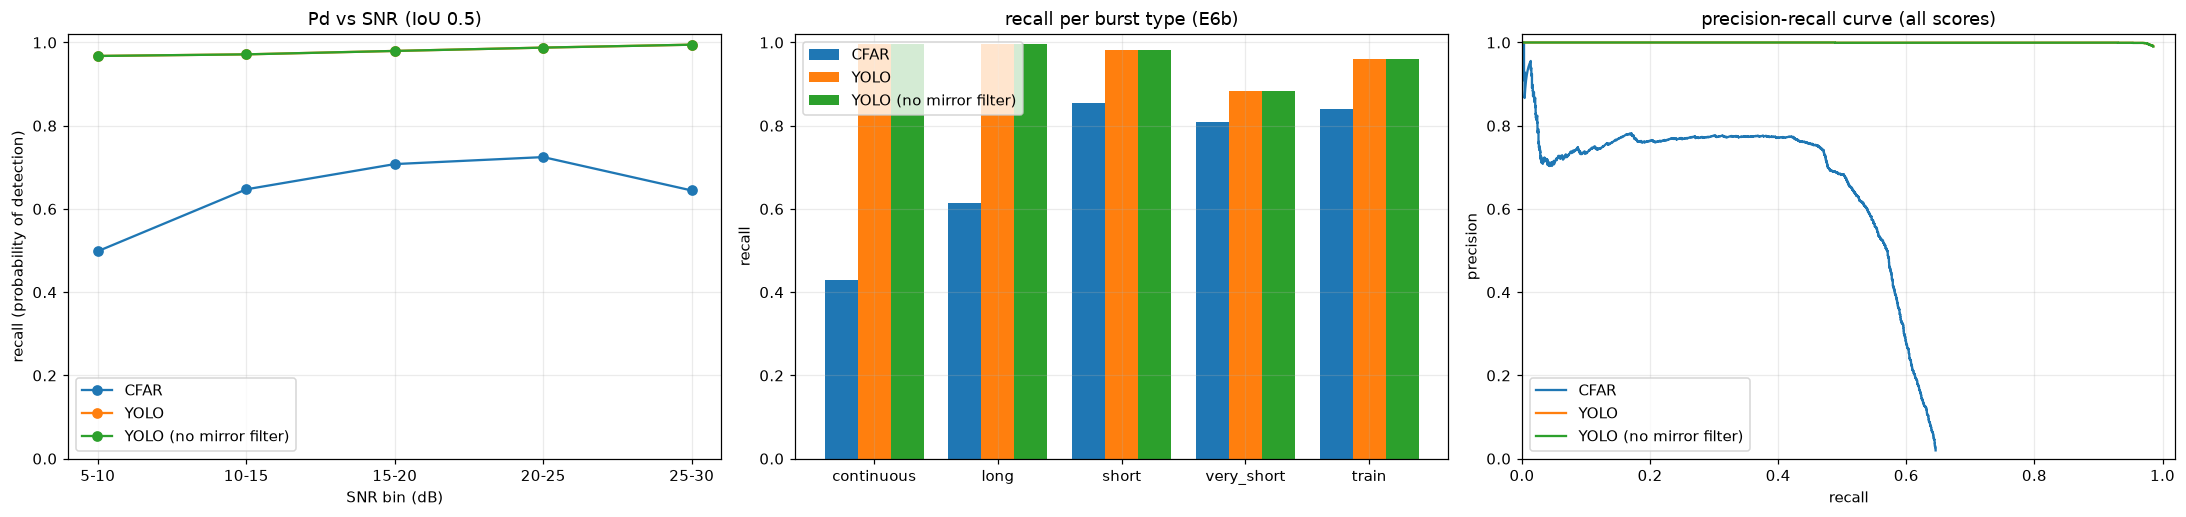

localization error of the matched boxes (test):


,median |center error| (Hz),median |bandwidth ratio - 1|,median |start error| (ms),median |end error| (ms)
CFAR,625.0,0.176,0.0,0.4
YOLO,625.0,0.000,0.0,0.0
YOLO (no mirror filter),625.0,0.000,0.0,0.0


In [6]:
BURSTS = ["continuous", "long", "short", "very_short", "train"]
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
w = 0.8 / len(DET_RESULTS)
for n, (d, (gt, pr)) in enumerate(DET_RESULTS.items()):
    g = add_snr_bin(gt.copy(), "snr")
    ax[0].plot(SNR_LABELS, g.groupby("snr_bin", observed=False).detected.mean().reindex(SNR_LABELS).values, marker="o", label=d)
    ax[1].bar(np.arange(len(BURSTS)) + n * w, gt.groupby("burst").detected.mean().reindex(BURSTS).values, width=w, label=d)
    p, r = pr_curve("test", d)
    ax[2].plot(r, p, label=d)
ax[0].set_xlabel("SNR bin (dB)")
ax[0].set_ylabel("recall (probability of detection)")
ax[0].set_ylim(0, 1.02)
ax[0].set_title("Pd vs SNR (IoU 0.5)")
ax[0].legend()
ax[1].set_xticks(np.arange(len(BURSTS)) + w * (len(DET_RESULTS) - 1) / 2, BURSTS)
ax[1].set_ylabel("recall")
ax[1].set_ylim(0, 1.02)
ax[1].set_title("recall per burst type (E6b)")
ax[1].legend()
ax[2].set_xlabel("recall")
ax[2].set_ylabel("precision")
ax[2].set_xlim(0, 1.02)
ax[2].set_ylim(0, 1.02)
ax[2].set_title("precision-recall curve (all scores)")
ax[2].legend()
plt.tight_layout()
plt.show()

loc = {}
for d, (gt, pr) in DET_RESULTS.items():
    m = pr[pr.tp] if len(pr) and pr.tp.any() else None
    if m is not None:
        loc[d] = {"median |center error| (Hz)": m.df_hz.abs().median(), "median |bandwidth ratio - 1|": (m.bw_ratio - 1).abs().median(),
                  "median |start error| (ms)": m.dt0_ms.abs().median(), "median |end error| (ms)": m.dt1_ms.abs().median()}
print("localization error of the matched boxes (test):")
display(pd.DataFrame(loc).T)


## 3. Protocol classification (E3)

Each classifier is run on the **ground-truth boxes** of the frozen `test` set, so the result isolates classification from detection. Reported: accuracy, macro-F1, per-protocol F1, the coarse-group accuracy (PSK and QAM merged, the level a magnitude spectrogram can realistically separate), confusion matrices and accuracy vs SNR. PSK vs QAM is expected to be the weak point of the spectrogram models.

In [7]:
GT_CACHE = {}


def gt_box_predictions(set_name, clf_name):
    """Run a classifier on the ground-truth boxes of a set. Returns (table: scene, family_id, snr), probabilities, logits (NaN if none)."""
    key = (set_name, clf_name)
    if key not in GT_CACHE:
        rd, fn = READERS[set_name], CLASSIFIERS[clf_name]
        tabs, P, L = [], [], []
        for i in tqdm(range(len(rd)), desc=f"{clf_name} on {set_name}"):
            g = rd.boxes(i)
            if len(g) == 0:
                continue
            boxes = [tuple(int(v) for v in b) for b in g[["box_x0", "box_y0", "box_x1", "box_y1"]].to_numpy()]
            probs, logits = fn(rd.spec_db(i), boxes, rd.iq(i) if CLF_NEEDS_IQ[clf_name] else None)
            P.append(probs)
            L.append(np.full_like(probs, np.nan) if logits is None else logits)
            tabs.append(pd.DataFrame(dict(scene=i, family_id=g.family_id.to_numpy(), snr=g.snr_db.to_numpy(), cls=g.class_name.to_numpy())))
        GT_CACHE[key] = (pd.concat(tabs, ignore_index=True), np.concatenate(P), np.concatenate(L))
    return GT_CACHE[key]


COARSE = np.array([0, 1, 1, 1])                 # wideband (LTE) | narrowband (DMR, P25, TETRA)
CLS_RESULTS, rows = {}, {}
for c in CLASSIFIERS:
    df, P, _ = gt_box_predictions("test", c)
    k = df.family_id.to_numpy() <= len(FAMILIES)
    y, yhat = df.family_id.to_numpy()[k] - 1, P[k].argmax(1)
    CLS_RESULTS[c] = cls_metrics(y, yhat, df.snr.to_numpy()[k])
    rows[c] = dict(accuracy=CLS_RESULTS[c]["accuracy"], macro_f1=CLS_RESULTS[c]["macro_f1"],
                   coarse_accuracy=float((COARSE[y] == COARSE[yhat]).mean()), boxes=len(y))
CLS_TABLE = pd.DataFrame(rows).T
display(CLS_TABLE)
print("per-protocol F1 (test):")
display(pd.DataFrame({c: {f: v["f1"] for f, v in m["per_class"].items()} for c, m in CLS_RESULTS.items()}).rename_axis("protocol"))

GBM on test:   0%|                                                                                                                                                                      | 0/1500 [00:00<?, ?it/s]

GBM on test:   1%|█▎                                                                                                                                                          | 13/1500 [00:00<00:14, 101.04it/s]

GBM on test:   3%|█████▏                                                                                                                                                      | 50/1500 [00:00<00:06, 239.66it/s]

GBM on test:   6%|█████████                                                                                                                                                   | 87/1500 [00:00<00:04, 293.71it/s]

GBM on test:   8%|████████████▊                                                                                                                                              | 124/1500 [00:00<00:04, 320.11it/s]

GBM on test:  11%|█████████████████▊                                                                                                                                         | 172/1500 [00:00<00:03, 372.74it/s]

... (138 outputs left out)

ResNet on test: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:11<00:00, 126.72it/s]

,accuracy,macro_f1,coarse_accuracy,boxes
GBM,0.924,0.913,1.0,3142.0
ResNet,0.982,0.980,1.0,3142.0


per-protocol F1 (test):


,GBM,ResNet
protocol,,
LTE,1.000,1.000
DMR,0.870,0.965
P25,0.784,0.957
TETRA,0.999,1.000


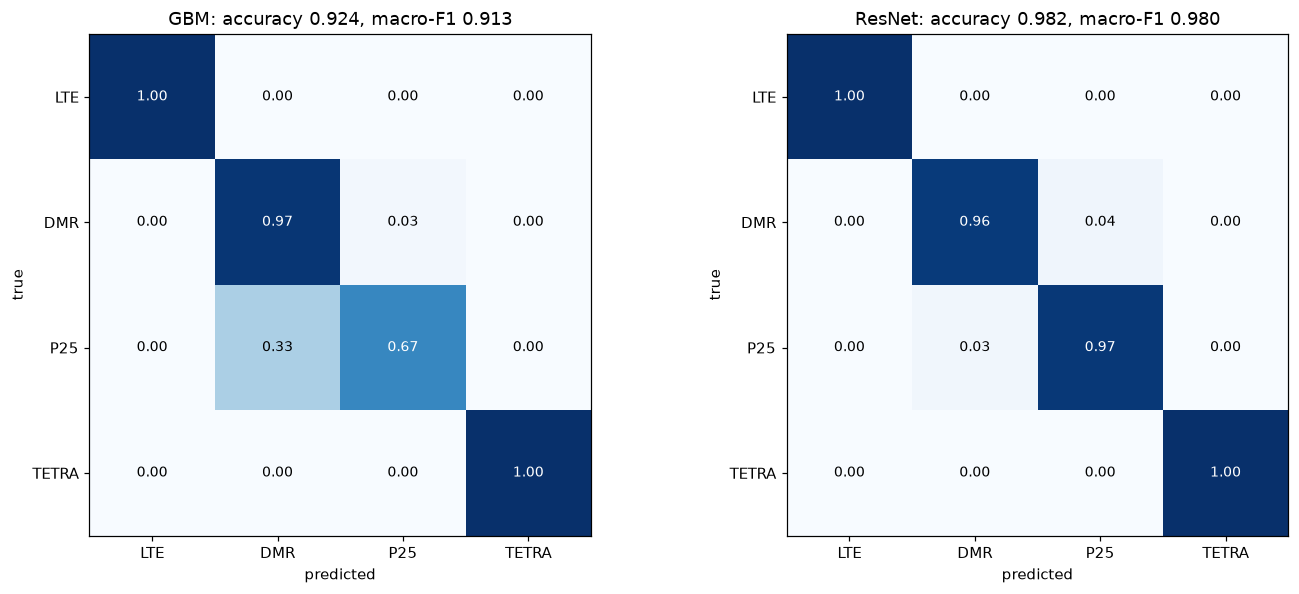

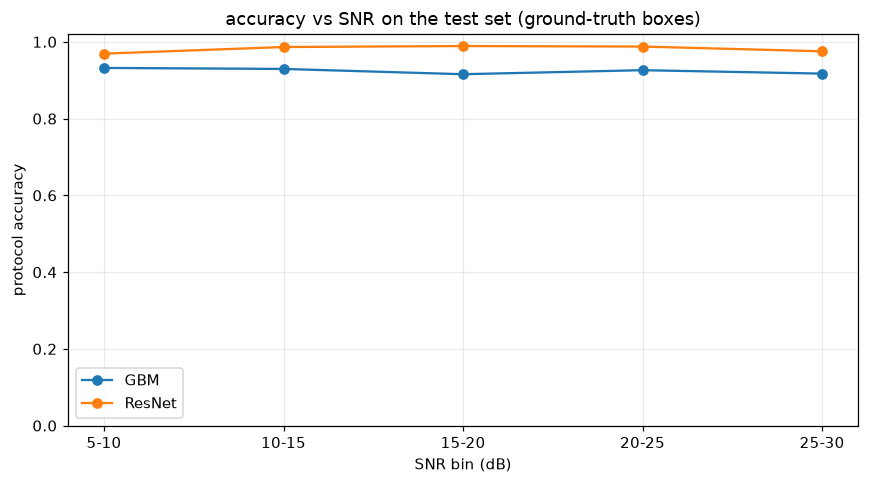

In [8]:
fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(6.5 * len(CLASSIFIERS), 5.5), squeeze=False)
for ax, (c, m) in zip(axes[0], CLS_RESULTS.items()):
    cm = np.array(m["confusion"], float)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)                        # rows sum to 1: recall per true family
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    ax.grid(False)
    for i in range(len(FAMILIES)):
        for j in range(len(FAMILIES)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(FAMILIES)), FAMILIES)
    ax.set_yticks(range(len(FAMILIES)), FAMILIES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{c}: accuracy {m['accuracy']:.3f}, macro-F1 {m['macro_f1']:.3f}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for c, m in CLS_RESULTS.items():
    a = m["acc_by_snr"]
    ax.plot(list(a), [v["acc"] for v in a.values()], marker="o", label=c)
ax.set_xlabel("SNR bin (dB)")
ax.set_ylabel("protocol accuracy")
ax.set_ylim(0, 1.02)
ax.set_title("accuracy vs SNR on the test set (ground-truth boxes)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. End-to-end pipelines

A pipeline is a detector plus a way to assign a protocol to each detected box:

- **two-stage** `detector + classifier`: the detector gives boxes, the classifier decides the protocol from a crop around each box (CFAR or YOLO boxes with GBM or ResNet),
- **single-stage** `YOLO (single-stage)`: the 4-class YOLO model predicts box and protocol together.

A prediction counts as correct only if its box matches a true box at IoU 0.5 **and** its protocol is right (class-aware F1). The pipeline with the highest class-aware F1 on `test` becomes the **best algorithm** (`BEST`), which Section 10 applies to new samples.

In [9]:
def apply_pipeline(db, iq, pname, dets):
    """Detections of one scene -> [dict(box, score, family = class index, prob)]. The family comes from the classifier
    (two-stage) or from the detector itself (single-stage)."""
    det_name, clf_name = PIPELINES[pname]
    dets = op_filter(dets, det_name)
    if not dets:
        return []
    boxes = [d["box"] for d in dets]
    probs = CLASSIFIERS[clf_name](db, boxes, iq)[0] if clf_name else np.eye(len(FAMILIES))[[d["cls"] for d in dets]]
    if pname in REFINE_PIPES and iq is not None:                  # DMR vs P25 from the IQ: GBM probabilities restricted to those two classes
        a_, b_ = FAMILIES.index("DMR"), FAMILIES.index("P25")
        probs = np.array(probs, float)
        sel = [k for k, p in enumerate(probs) if int(p.argmax()) in (a_, b_)]
        if sel:
            pg = REFINER.predict_proba(db, [boxes[k] for k in sel], iq)
            for k, p in zip(sel, pg):
                pick = a_ if p[a_] >= p[b_] else b_
                probs[k] = 0.0
                probs[k, pick] = p[pick] / max(p[a_] + p[b_], 1e-9)
    return [dict(box=d["box"], score=d["score"], family=int(p.argmax()), prob=float(p.max())) for d, p in zip(dets, probs)]


PIPE_CACHE = {}


def run_pipeline(set_name, pname):
    key = (set_name, pname)
    if key not in PIPE_CACHE:
        det_name, clf_name = PIPELINES[pname]
        rd, dets_all = READERS[set_name], run_detector(set_name, det_name)
        need_iq = (clf_name is not None and CLF_NEEDS_IQ[clf_name]) or pname in REFINE_PIPES
        out = []
        for i in tqdm(range(len(rd)), desc=f"{pname} on {set_name}"):
            if not op_filter(dets_all[i], det_name):
                out.append([])
                continue
            out.append(apply_pipeline(rd.spec_db(i), rd.iq(i) if need_iq else None, pname, dets_all[i]))
        PIPE_CACHE[key] = out
    return PIPE_CACHE[key]


def eval_pipeline(set_name, pname, thr=0.5):
    """Class-aware scores: a matched box with the wrong family counts as one false alarm and one miss."""
    rd = READERS[set_name]
    tp = tpc = n_pred = n_gt = 0
    for i, preds in enumerate(run_pipeline(set_name, pname)):
        g, gb = gt_arrays(rd, i)
        n_gt, n_pred = n_gt + len(g), n_pred + len(preds)
        fam = g.family_id.to_numpy() - 1
        m = match_detections([p["box"] for p in preds], [p["score"] for p in preds], gb, thr)
        for p, k in zip(preds, m):
            if k >= 0:
                tp, tpc = tp + 1, tpc + int(p["family"] == fam[k])
    return dict(det_f1=2 * tp / max(n_pred + n_gt, 1), class_f1=2 * tpc / max(n_pred + n_gt, 1), cls_acc_on_matched=tpc / max(tp, 1),
                n_pred=n_pred, n_gt=n_gt)


PIPE_TABLE = pd.DataFrame({p: eval_pipeline("test", p) for p in PIPELINES}).T
display(PIPE_TABLE.sort_values("class_f1", ascending=False))
BEST = PIPE_TABLE["class_f1"].idxmax()
print(f"best pipeline on the test set (class-aware F1): {BEST}")

CFAR + GBM on test:   0%|                                                                                                                                                               | 0/1500 [00:00<?, ?it/s]

CFAR + GBM on test:   1%|█                                                                                                                                                     | 10/1500 [00:00<00:15, 99.21it/s]

CFAR + GBM on test:   1%|██                                                                                                                                                    | 20/1500 [00:00<00:17, 86.08it/s]

CFAR + GBM on test:   2%|██▉                                                                                                                                                   | 29/1500 [00:00<00:20, 70.29it/s]

CFAR + GBM on test:   3%|████▉                                                                                                                                                | 50/1500 [00:00<00:12, 113.85it/s]

CFAR + GBM on test:   4%|██████▎                                                                                                                                               | 63/1500 [00:00<00:14, 97.57it/s]

... (825 outputs left out)

YOLO (single-stage) on test:  85%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████▉                     | 1270/1500 [00:00<00:00, 6248.91it/s]

YOLO (single-stage) on test: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:00<00:00, 6199.81it/s]

,det_f1,class_f1,cls_acc_on_matched,n_pred,n_gt
YOLO (single-stage),0.987,0.975,0.987,3095.0,3142.0
YOLO + ResNet,0.987,0.971,0.984,3095.0,3142.0
YOLO + GBM,0.987,0.897,0.908,3095.0,3142.0
CFAR + ResNet,0.039,0.038,0.979,102137.0,3142.0
CFAR + GBM,0.039,0.026,0.681,102137.0,3142.0


best pipeline on the test set (class-aware F1): YOLO (single-stage)


## 5. Robustness to unseen impairments (E4)

`test_robust` is generated with receiver conditions never used in training: 10 ppm oscillator error, 8-bit ADC and Rayleigh fading. The table compares every detector, classifier and the best pipeline on `test` (seen conditions) and `test_robust`. A large drop means the model depends on the simulator's exact impairments, which is a warning for the sim-to-real step.


CFAR on test_robust:   0%|                                                                                                                                                                | 0/16 [00:00<?, ?it/s]

CFAR on test_robust:   6%|█████████▌                                                                                                                                              | 1/16 [00:02<00:36,  2.46s/it]

CFAR on test_robust:  12%|███████████████████                                                                                                                                     | 2/16 [00:04<00:34,  2.43s/it]

CFAR on test_robust:  19%|████████████████████████████▌                                                                                                                           | 3/16 [00:07<00:31,  2.41s/it]

CFAR on test_robust:  25%|██████████████████████████████████████                                                                                                                  | 4/16 [00:09<00:29,  2.44s/it]

CFAR on test_robust:  31%|███████████████████████████████████████████████▌                                                                                                        | 5/16 [00:12<00:26,  2.44s/it]

... (144 outputs left out)

YOLO (single-stage) on test_robust:   0%|                                                                                                                                               | 0/1000 [00:00<?, ?it/s]

YOLO (single-stage) on test_robust:  63%|██████████████████████████████████████████████████████████████████████████████████                                                 | 626/1000 [00:00<00:00, 6257.13it/s]

YOLO (single-stage) on test_robust: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 6114.67it/s]

set,test,test_robust,change
metric,,,
CFAR: detection F1,0.039,0.038,-1.015e-04
GBM: protocol accuracy,0.924,0.910,-1.466e-02
ResNet: protocol accuracy,0.982,0.979,-2.863e-03
YOLO (no mirror filter): detection F1,0.987,0.923,-6.412e-02
YOLO (single-stage) (best): class-aware F1,0.975,0.951,-2.416e-02
YOLO: detection F1,0.987,0.967,-2.007e-02


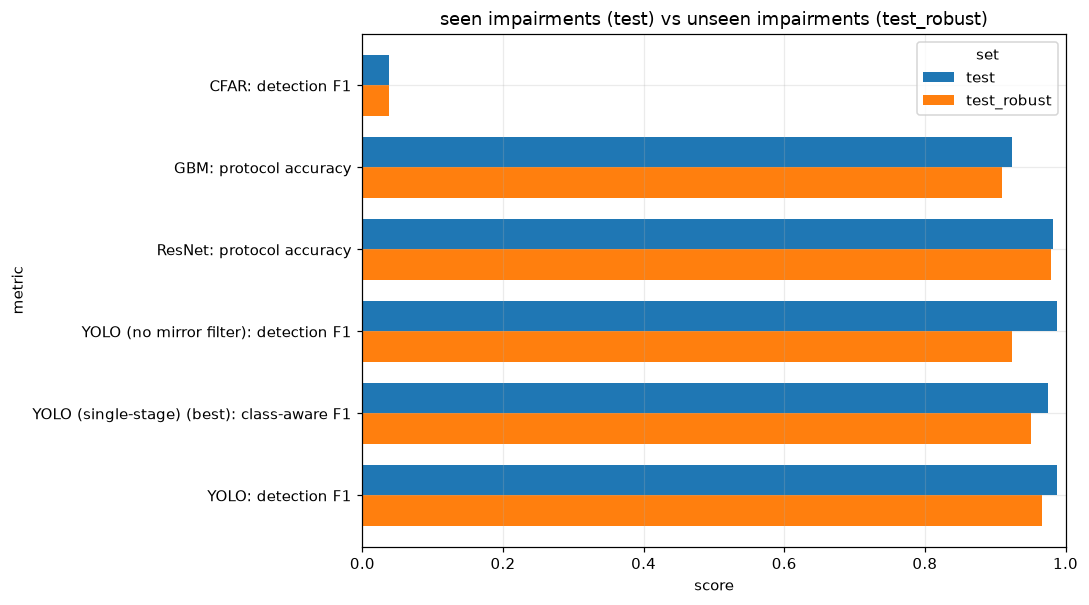

In [10]:
rows = []
for d in DETECTORS:
    for s in ("test", "test_robust"):
        gt, pr = eval_detection(s, d)
        rows.append(dict(metric=f"{d}: detection F1", set=s, value=det_summary(gt, pr)["f1"]))
for c in CLASSIFIERS:
    for s in ("test", "test_robust"):
        df, P, _ = gt_box_predictions(s, c)
        k = df.family_id.to_numpy() <= len(FAMILIES)
        rows.append(dict(metric=f"{c}: protocol accuracy", set=s, value=float((P[k].argmax(1) == df.family_id.to_numpy()[k] - 1).mean())))
for s in ("test", "test_robust"):
    rows.append(dict(metric=f"{BEST} (best): class-aware F1", set=s, value=eval_pipeline(s, BEST)["class_f1"]))
ROBUST_TABLE = pd.DataFrame(rows).pivot(index="metric", columns="set", values="value")[["test", "test_robust"]]
ROBUST_TABLE["change"] = ROBUST_TABLE["test_robust"] - ROBUST_TABLE["test"]
display(ROBUST_TABLE)

ax = ROBUST_TABLE[["test", "test_robust"]].plot.barh(figsize=(10, 0.6 * len(ROBUST_TABLE) + 2), width=0.75)
ax.set_xlim(0, 1)
ax.set_xlabel("score")
ax.set_title("seen impairments (test) vs unseen impairments (test_robust)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Open-set: unknown signals (E5)

`test_openset` holds NBFM (analog voice), WFM (broadcast FM) and GSM, which nothing was trained on, and also the usual distractors (AM, CW, POCSAG). Three views:

1. **AUROC** of two scores on the classifier's ground-truth boxes: **max-softmax** (baseline) and the **energy score** (logsumexp of the logits, ResNet only). The unknown class is the held-out NBFM / WFM / GSM.
2. **Calibrated operating point:** the threshold on the energy score comes from `calibration.json`, written by `train_classifier.py` from the *validation boxes of the known protocols only* (it keeps 95% of them). This table shows how many known test boxes it keeps and how many boxes of every unknown signal it rejects.
3. **Detectors:** the share of the unknown boxes that a detection at the operating confidence lands on (IoU >= 0.5), and with which protocol. A detector that never saw analog voice but always calls NBFM a DMR channel has a fire rate near 1.

GBM on test_openset:   0%|                                                                                                                                                              | 0/1000 [00:00<?, ?it/s]

GBM on test_openset:   3%|████▎                                                                                                                                               | 29/1000 [00:00<00:03, 286.91it/s]

GBM on test_openset:   7%|██████████▏                                                                                                                                         | 69/1000 [00:00<00:02, 351.03it/s]

GBM on test_openset:  11%|███████████████▋                                                                                                                                   | 107/1000 [00:00<00:02, 360.29it/s]

GBM on test_openset:  14%|█████████████████████▏                                                                                                                             | 144/1000 [00:00<00:02, 357.94it/s]

GBM on test_openset:  19%|███████████████████████████▎                                                                                                                       | 186/1000 [00:00<00:02, 375.87it/s]

... (98 outputs left out)

ResNet on test_openset:  98%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████   | 980/1000 [00:08<00:00, 110.76it/s]

ResNet on test_openset:  99%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▊ | 992/1000 [00:08<00:00, 107.16it/s]

ResNet on test_openset: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:08<00:00, 117.97it/s]

,n_known,n_unknown,auroc,fpr_at_95_tpr
method,,,,
GBM (max-softmax),3142,1294,0.427,0.919
ResNet (max-softmax),3142,1294,0.934,0.151
ResNet (energy),3142,1294,0.959,0.089


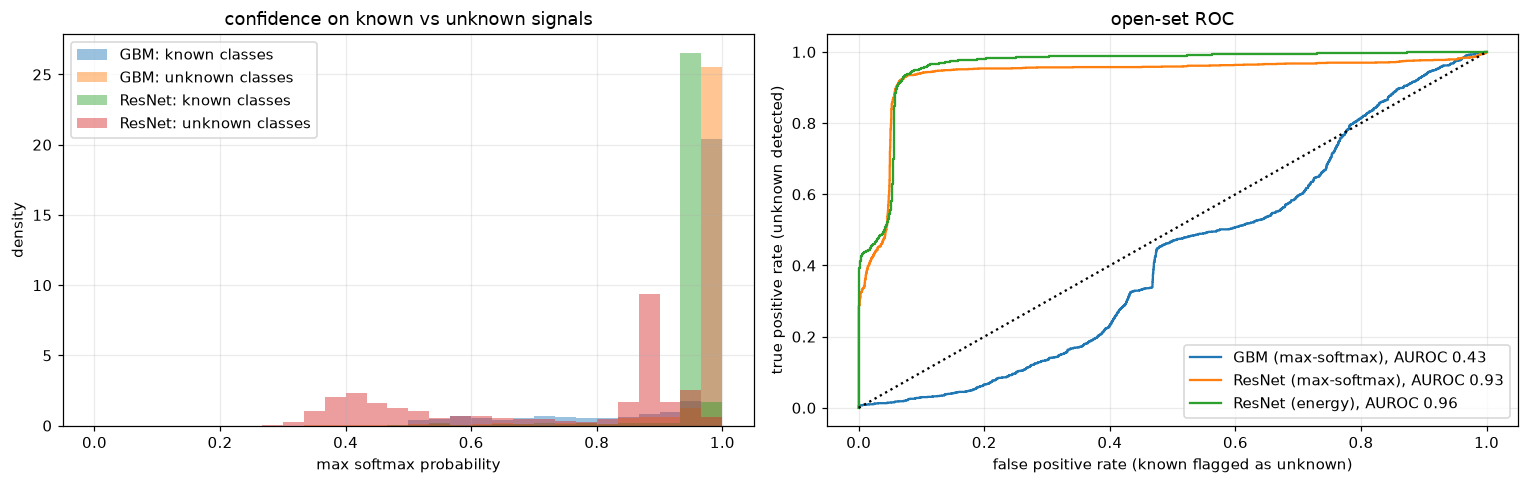

In [11]:
HELD_OUT = ["NBFM", "WFM", "GSM"]


def ood_metrics(s_known, s_unknown):
    """Score: higher = more 'unknown'. Unknown is the positive class."""
    y = np.r_[np.zeros(len(s_known)), np.ones(len(s_unknown))]
    s = np.r_[s_known, s_unknown]
    fpr, tpr, _ = roc_curve(y, s)
    return dict(auroc=float(roc_auc_score(y, s)), fpr_at_95_tpr=float(fpr[np.searchsorted(tpr, 0.95)])), (fpr, tpr)


rows, curves, hists = [], {}, {}
for c in CLASSIFIERS:
    dk, Pk, Lk = gt_box_predictions("test", c)                   # known classes: the main test set
    do, Po, Lo = gt_box_predictions("test_openset", c)           # unknown boxes (NBFM, WFM, GSM) carry the unknown id
    kn = dk.family_id.to_numpy() <= len(FAMILIES)
    un = do.cls.isin(HELD_OUT).to_numpy()                        # held-out NBFM / WFM / GSM (distractors are looked at separately below)
    scores = {"max-softmax": (-Pk[kn].max(1), -Po[un].max(1))}
    if not np.isnan(Lk).any():                                   # the energy score needs logits (ResNet only)
        scores["energy"] = (-logsumexp(Lk[kn], axis=1), -logsumexp(Lo[un], axis=1))
    for name, (sk, su) in scores.items():
        m, curve = ood_metrics(sk, su)
        rows.append(dict(method=f"{c} ({name})", n_known=int(kn.sum()), n_unknown=int(un.sum()), **m))
        curves[f"{c} ({name})"], hists[(c, name)] = curve, (sk, su)
OOD_TABLE = pd.DataFrame(rows).set_index("method")
display(OOD_TABLE)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for (c, name), (sk, su) in hists.items():
    if name == "max-softmax":
        ax[0].hist(-sk, bins=30, range=(0, 1), alpha=0.45, density=True, label=f"{c}: known classes")
        ax[0].hist(-su, bins=30, range=(0, 1), alpha=0.45, density=True, label=f"{c}: unknown classes")
ax[0].set_xlabel("max softmax probability")
ax[0].set_ylabel("density")
ax[0].set_title("confidence on known vs unknown signals")
ax[0].legend()
for key, (fpr, tpr) in curves.items():
    ax[1].plot(fpr, tpr, label=f"{key}, AUROC {OOD_TABLE.loc[key, 'auroc']:.2f}")
ax[1].plot([0, 1], [0, 1], "k:")
ax[1].set_xlabel("false positive rate (known flagged as unknown)")
ax[1].set_ylabel("true positive rate (unknown detected)")
ax[1].set_title("open-set ROC")
ax[1].legend()
plt.tight_layout()
plt.show()

In [12]:
# ---- the calibrated operating point of the ResNet (threshold from val, known protocols only)
OPEN_OP_TABLE = pd.DataFrame()
cal = load_calibration(RUNS / CLASSIFIER_RUN)
if "ResNet" in CLASSIFIERS and cal is not None:
    thr = cal["energy_threshold"]
    dk, Pk, Lk = gt_box_predictions("test", "ResNet")
    do, Po, Lo = gt_box_predictions("test_openset", "ResNet")
    kn = dk.family_id.to_numpy() <= len(FAMILIES)
    ek, eo = energy_score(Lk[kn]), energy_score(Lo)
    rows = {"known protocols (test): kept": dict(boxes=int(kn.sum()), share=float((ek >= thr).mean()))}
    for name in HELD_OUT + ["AM", "CW", "POCSAG"]:
        sel = (do.cls == name).to_numpy()
        if sel.any():
            rows[f"{name} (test_openset): rejected as unknown"] = dict(boxes=int(sel.sum()), share=float((eo[sel] < thr).mean()))
    OPEN_OP_TABLE = pd.DataFrame(rows).T
    print(f"energy threshold {thr:.3f} (calibrated on val, keeps {cal['accept_known']:.0%} of the known boxes)")
    display(OPEN_OP_TABLE)
else:
    print("no calibration.json next to the classifier: retrain with train_classifier.py to get the calibrated operating point")

# ---- do the detectors fire on unknown signals?
UNKNOWN_FIRE = {}
rd = READERS["test_openset"]
for d_name in DETECTORS:
    if d_name == "CFAR":
        continue
    fired, labels = {}, {}
    multi = not getattr(DETECTORS[d_name], "single_class", True)        # a 4-class detector also says which protocol it fired with
    for i, dets in enumerate(run_detector("test_openset", d_name)):
        dets = op_filter(dets, d_name)
        g = rd.boxes(i)
        g = g[g.family_id > len(FAMILIES)].reset_index(drop=True)
        if len(g) == 0:
            continue
        gb = g[BOX_COLS].to_numpy()
        m = match_detections([d["box"] for d in dets], [d["score"] for d in dets], gb, 0.5)
        hit = {int(k): p for p, k in enumerate(m) if k >= 0}
        for k, r in enumerate(g.itertuples()):
            fired.setdefault(r.class_name, []).append(k in hit)
            if k in hit and multi:
                labels.setdefault(r.class_name, []).append(FAMILIES[dets[hit[k]]["cls"]])
    UNKNOWN_FIRE[d_name] = {n: dict(boxes=len(v), fire_rate=float(np.mean(v)),
                                    most_common_label=(pd.Series(labels[n]).mode().iat[0] if n in labels else "-")) for n, v in fired.items()}
print("share of the unknown boxes that a detection lands on (IoU >= 0.5), at the operating confidence:")
display(pd.concat({d: pd.DataFrame(v).T for d, v in UNKNOWN_FIRE.items()}))

energy threshold 1.558 (calibrated on val, keeps 95% of the known boxes)


,boxes,share
known protocols (test): kept,3142.0,0.945
NBFM (test_openset): rejected as unknown,388.0,0.580
WFM (test_openset): rejected as unknown,472.0,1.000
GSM (test_openset): rejected as unknown,434.0,0.394


YOLO on test_openset:   0%|                                                                                                                                                               | 0/16 [00:00<?, ?it/s]

YOLO on test_openset:   6%|█████████▍                                                                                                                                             | 1/16 [00:00<00:07,  1.98it/s]

YOLO on test_openset:  12%|██████████████████▉                                                                                                                                    | 2/16 [00:00<00:06,  2.02it/s]

YOLO on test_openset:  19%|████████████████████████████▎                                                                                                                          | 3/16 [00:01<00:06,  2.05it/s]

... (30 outputs left out)

YOLO (no mirror filter) on test_openset: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:07<00:00,  2.31it/s]

YOLO (no mirror filter) on test_openset: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:07<00:00,  2.12it/s]

share of the unknown boxes that a detection lands on (IoU >= 0.5), at the operating confidence:


boxes fire_rate most_common_label
YOLO                    NBFM   388     0.588               P25
                        WFM    472       0.0                 -
                        GSM    434       0.0                 -
YOLO (no mirror filter) NBFM   388     0.588               P25
                        WFM    472       0.0                 -
                        GSM    434       0.0                 -

## 7. SNR stress: outside the training range

`test_snr_stress` holds scenes with SNR below 5 dB and above 30 dB. Together with `test` (5 to 30 dB) it shows how accuracy and detection recall change with SNR, including the regions the models never saw in training (shaded red). This is for robustness reporting only.


GBM on test_snr_stress:   0%|                                                                                                                                                           | 0/1000 [00:00<?, ?it/s]

GBM on test_snr_stress:   3%|████                                                                                                                                             | 28/1000 [00:00<00:03, 268.72it/s]

GBM on test_snr_stress:   6%|████████▊                                                                                                                                        | 61/1000 [00:00<00:03, 301.37it/s]

GBM on test_snr_stress:   9%|█████████████▍                                                                                                                                   | 93/1000 [00:00<00:02, 303.85it/s]

GBM on test_snr_stress:  12%|█████████████████▊                                                                                                                              | 124/1000 [00:00<00:02, 299.26it/s]

GBM on test_snr_stress:  16%|███████████████████████▏                                                                                                                        | 161/1000 [00:00<00:02, 323.73it/s]

... (159 outputs left out)

YOLO (no mirror filter) on test_snr_stress:  88%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████                | 14/16 [00:06<00:00,  2.02it/s]

YOLO (no mirror filter) on test_snr_stress:  94%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████        | 15/16 [00:07<00:00,  2.02it/s]

YOLO (no mirror filter) on test_snr_stress: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:07<00:00,  2.25it/s]

YOLO (no mirror filter) on test_snr_stress: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:07<00:00,  2.05it/s]

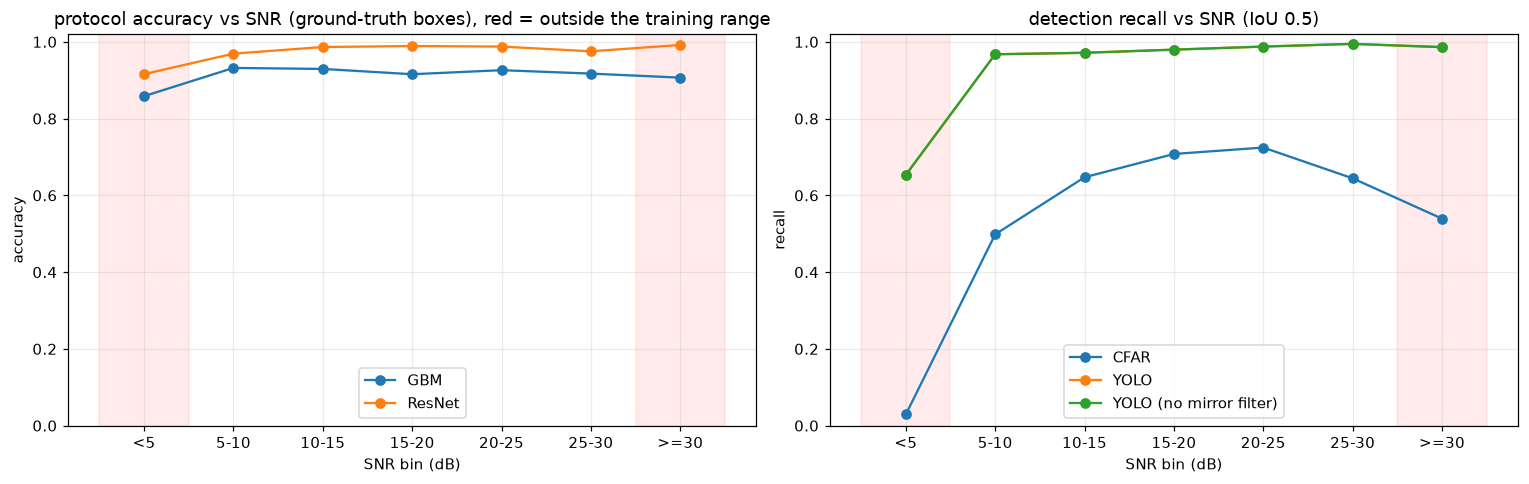

,GBM,ResNet
SNR bin (dB),,
<5,0.858,0.916
5-10,0.932,0.969
10-15,0.929,0.986
15-20,0.916,0.989
20-25,0.926,0.988
25-30,0.917,0.975
>=30,0.907,0.992


In [13]:
STRESS = "test_snr_stress"
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
acc_table = {}
for c in CLASSIFIERS:
    parts = []
    for s in ("test", STRESS):                                    # test covers 5 to 30 dB, the stress set the ranges outside
        df, P, _ = gt_box_predictions(s, c)
        k = df.family_id.to_numpy() <= len(FAMILIES)
        parts.append(pd.DataFrame(dict(snr=df.snr.to_numpy()[k], ok=P[k].argmax(1) == df.family_id.to_numpy()[k] - 1)))
    d = add_snr_bin(pd.concat(parts, ignore_index=True), "snr")
    acc_table[c] = d.groupby("snr_bin", observed=False).ok.mean().reindex(SNR_LABELS)
    ax[0].plot(SNR_LABELS, acc_table[c].values, marker="o", label=c)
ax[0].set_title("protocol accuracy vs SNR (ground-truth boxes), red = outside the training range")
ax[0].set_xlabel("SNR bin (dB)")
ax[0].set_ylabel("accuracy")
ax[0].set_ylim(0, 1.02)
ax[0].legend()

for d_name in DETECTORS:
    g = add_snr_bin(pd.concat([eval_detection(s, d_name)[0] for s in ("test", STRESS)], ignore_index=True), "snr")
    ax[1].plot(SNR_LABELS, g.groupby("snr_bin", observed=False).detected.mean().reindex(SNR_LABELS).values, marker="o", label=d_name)
ax[1].set_title("detection recall vs SNR (IoU 0.5)")
ax[1].set_xlabel("SNR bin (dB)")
ax[1].set_ylabel("recall")
ax[1].set_ylim(0, 1.02)
ax[1].legend()
for a in ax:
    a.axvspan(-0.5, 0.5, color="red", alpha=0.08)
    a.axvspan(5.5, 6.5, color="red", alpha=0.08)
plt.tight_layout()
plt.show()
display(pd.DataFrame(acc_table).rename_axis("SNR bin (dB)"))

## 8. Summary and the best algorithm

All results in one place. The **best algorithm** is the end-to-end pipeline with the highest class-aware F1 on the frozen `test` set (a detection counts only when its box matches at IoU 0.5 **and** its protocol is correct). It is the algorithm used in the final Test section.

In [14]:
board = PIPE_TABLE.copy()
board = board.sort_values("class_f1", ascending=False)
print("End-to-end leaderboard on the frozen test set (IoU 0.5):")
display(board)
print("\nDetectors (test):")
display(DET_TABLE)
print("\nClassifiers on ground-truth boxes (test):")
display(CLS_TABLE)
print("\nOpen-set (unknown classes):")
display(OOD_TABLE)
if len(OPEN_OP_TABLE):
    print("calibrated ResNet operating point:")
    display(OPEN_OP_TABLE)
print("\nRobustness (seen vs unseen impairments):")
display(ROBUST_TABLE)

print(f"\nBest algorithm: {BEST}  (class-aware F1 {board.loc[BEST, 'class_f1']:.3f}, detection F1 {board.loc[BEST, 'det_f1']:.3f}, "
      f"classification accuracy on matched boxes {board.loc[BEST, 'cls_acc_on_matched']:.3f})")
print("Reminder: these numbers come from synthetic data. Validate on real LTE / DMR / P25 / TETRA captures before trusting absolute values (R&D Section 8).")

save_json(dict(best_pipeline=BEST, max_scenes=MAX_SCENES, device=str(DEVICE), leaderboard=board.to_dict("index"), detectors=DET_TABLE.to_dict("index"),
               classifiers=CLS_TABLE.to_dict("index"), open_set=OOD_TABLE.to_dict("index"), open_set_operating=OPEN_OP_TABLE.to_dict("index"), unknown_fire_rate=UNKNOWN_FIRE,
               robustness=ROBUST_TABLE.reset_index().to_dict("records")), OUT / "summary.json")
print("saved", OUT / "summary.json")

End-to-end leaderboard on the frozen test set (IoU 0.5):


,det_f1,class_f1,cls_acc_on_matched,n_pred,n_gt
YOLO (single-stage),0.987,0.975,0.987,3095.0,3142.0
YOLO + ResNet,0.987,0.971,0.984,3095.0,3142.0
YOLO + GBM,0.987,0.897,0.908,3095.0,3142.0
CFAR + ResNet,0.039,0.038,0.979,102137.0,3142.0
CFAR + GBM,0.039,0.026,0.681,102137.0,3142.0



Detectors (test):


,precision,recall,f1,n_pred,n_gt
CFAR,0.020,0.646,0.039,102137.0,3142.0
YOLO,0.995,0.980,0.987,3095.0,3142.0
YOLO (no mirror filter),0.995,0.980,0.987,3095.0,3142.0



Classifiers on ground-truth boxes (test):


,accuracy,macro_f1,coarse_accuracy,boxes
GBM,0.924,0.913,1.0,3142.0
ResNet,0.982,0.980,1.0,3142.0


... (3 outputs left out)

,boxes,share
known protocols (test): kept,3142.0,0.945
NBFM (test_openset): rejected as unknown,388.0,0.580
WFM (test_openset): rejected as unknown,472.0,1.000
GSM (test_openset): rejected as unknown,434.0,0.394



Robustness (seen vs unseen impairments):


set,test,test_robust,change
metric,,,
CFAR: detection F1,0.039,0.038,-1.015e-04
GBM: protocol accuracy,0.924,0.910,-1.466e-02
ResNet: protocol accuracy,0.982,0.979,-2.863e-03
YOLO (no mirror filter): detection F1,0.987,0.923,-6.412e-02
YOLO (single-stage) (best): class-aware F1,0.975,0.951,-2.416e-02
YOLO: detection F1,0.987,0.967,-2.007e-02



Best algorithm: YOLO (single-stage)  (class-aware F1 0.975, detection F1 0.987, classification accuracy on matched boxes 0.987)
Reminder: these numbers come from synthetic data. Validate on real LTE / DMR / P25 / TETRA captures before trusting absolute values (R&D Section 8).
saved /Users/tohid/Desktop/RF-Signal-Detection/runs/evaluation/detector_run2/summary.json


## 9. Test

The best algorithm from Section 9 (chosen on the frozen `test` set by class-aware F1) is applied to **samples that are not in the dataset folder**. They are read from the folder `external_test/` next to this notebook (override with the environment variable `SPECTRUM_EXTERNAL`). The notebook refuses to run if that folder is inside the dataset folder.

**What you can put in `external_test/`**

| File | Meaning |
|---|---|
| `*.npy` complex | raw IQ at 2.56 MS/s, at least 197632 samples (77 ms) |
| `*.npy` shape `[n, 2]` | raw IQ as I and Q columns |
| `*.cfile` / `*.iq` | raw complex64 from GNU Radio or a USRP capture |
| `*.npy` float `[frames, 2048]` | spectrogram in dB (0 dB = noise floor) |
| `*.png` / `*.jpg` | grayscale spectrogram image, -10 to 40 dB mapped to 0 to 255 (the YOLO export convention) |

For IQ files at another sample rate set `SPECTRUM_INPUT_FS`. The spectrogram of raw IQ is shifted so that its median equals the dataset's noise floor, because a real receiver has an arbitrary gain. A file `<name>.json` next to a sample may hold its ground truth (a list of signals with `kind` = protocol, `family`, `center_hz`, `bw_hz`, `t0_ms`, `t1_ms`, `snr_db`).

**If the folder is empty**, three demo scenes are generated into it with a small independent generator (different pulse shaping, no PDCCH / reference-signal structure, different framing and seeds than `protocols.py`, so no model has seen them): LTE + DMR + TETRA, P25 + a DMR mobile burst + a TETRA slot burst, and a DMR and a P25 channel side by side (the hard pair). Their ground truth is drawn as dashed boxes and compared with the prediction. For real captures there is no ground truth, so check the plots by eye.

The demo scenes are cleaner than the dataset (no ADC quantisation, IQ imbalance or fading), and real captures will differ more: this section shows that the full chain runs on new data, it is not a measure of real-world accuracy (R&D Section 8).

In [15]:
from fractions import Fraction

from PIL import Image
from scipy.signal import fftconvolve, firwin, resample_poly

# ------------------------------------------------------------------ where the test samples live (never inside the dataset folder)
EXTERNAL_DIR = Path(os.environ.get("SPECTRUM_EXTERNAL", PROJECT_DIR / "external_test")).resolve()
for forbidden in (ROOT.resolve(), (PROJECT_DIR / "dataset").resolve()):
    if EXTERNAL_DIR == forbidden or forbidden in EXTERNAL_DIR.parents:
        raise ValueError(f"the test samples must be outside the dataset folder ({forbidden})")
EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FS = float(os.environ.get("SPECTRUM_INPUT_FS", FS))      # sample rate of your IQ files (resampled to 2.56 MS/s if different)
SUPPORTED = (".npy", ".cfile", ".iq", ".png", ".jpg", ".jpeg")
# the dataset's noise-floor level: raw IQ has an arbitrary gain, so its spectrogram is shifted until its median matches this value
REF_FLOOR_DB = float(np.median([np.median(READERS["test"].spec_db(i)) for i in range(min(200, len(READERS["test"])))]))


def load_sample(path):
    """Supported inputs:
       .npy complex64/128 (IQ), .npy [n, 2] (I, Q), .cfile / .iq (raw complex64, GNU Radio / USRP), at least 77 ms of IQ at INPUT_FS
       .npy float [frames, 2048] spectrogram in dB (or uint8 as stored in the dataset), .png / .jpg grayscale image (-10..40 dB -> 0..255)
       an optional <name>.json next to the file holds the ground truth (only the generated demo samples have one)."""
    path = Path(path)
    suf, iq, db = path.suffix.lower(), None, None
    if suf == ".npy":
        a = np.load(path)
        if np.iscomplexobj(a):
            iq = a.ravel().astype(np.complex64)
        elif a.ndim == 2 and a.shape[1] == 2:
            iq = (a[:, 0] + 1j * a[:, 1]).astype(np.complex64)
        elif a.ndim == 2:
            db = dequantize_db(a) if a.dtype == np.uint8 else a.astype(np.float32)
        else:
            raise ValueError(f"{path.name}: unsupported array shape {a.shape}")
    elif suf in (".cfile", ".iq"):
        iq = np.fromfile(path, np.complex64)
    elif suf in (".png", ".jpg", ".jpeg"):
        img = Image.open(path).convert("L")
        if img.size != (N_FFT, N_FRAMES):
            img = img.resize((N_FFT, N_FRAMES))
        db = gray_to_db(np.asarray(img))
    else:
        raise ValueError(f"unsupported file type: {path.name}")
    if iq is not None:
        if INPUT_FS != FS:
            fr = Fraction(FS / INPUT_FS).limit_denominator(1000)
            iq = resample_poly(iq, fr.numerator, fr.denominator).astype(np.complex64)
        if len(iq) < N_SAMPLES:
            raise ValueError(f"{path.name}: needs at least {N_SAMPLES} samples ({N_SAMPLES / FS * 1e3:.0f} ms at {FS:.0f} S/s), has {len(iq)}")
        iq = iq[:N_SAMPLES]
        db = spectrogram_db(iq)
        db = db + (REF_FLOOR_DB - float(np.median(db)))
    else:
        if db.shape[1] != N_FFT:
            raise ValueError(f"{path.name}: spectrogram must have {N_FFT} frequency bins, has {db.shape[1]}")
        db = db[:N_FRAMES]
        if db.shape[0] < N_FRAMES:
            db = np.pad(db, ((0, N_FRAMES - db.shape[0]), (0, 0)), constant_values=REF_FLOOR_DB)
    gt_file = path.with_suffix(".json")
    return dict(name=path.stem, db=db.astype(np.float32), iq=iq, gt=json.loads(gt_file.read_text()) if gt_file.exists() else None)


# ------------------------------------------------------------------ demo samples: a small independent generator
# Deliberately different from protocols.py (Gaussian / low-pass pulse shaping instead of raised cosine / RRC, a fully loaded LTE grid with
# no PDCCH / reference-signal / PSS structure, no sync words, new seeds, no ADC / IQ imbalance / fading), so these scenes are unseen by every model.
def _resample_to_fs(x, fs_in, n):
    fr = Fraction(FS / fs_in).limit_denominator(2000)
    return resample_poly(x, fr.numerator, fr.denominator)[8000:8000 + n]


def _fsk4(n, rng, unit_hz):
    nn = int((n + 12000) * 48_000 / FS) + 200
    f = np.repeat(rng.choice([-3.0, -1.0, 1.0, 3.0], nn // 10 + 2), 10)[:nn] * unit_hz
    g = np.hanning(12)
    f = np.convolve(f, g / g.sum(), mode="same")
    return _resample_to_fs(np.exp(2j * np.pi * np.cumsum(f) / 48_000), 48_000, n)


def _dqpsk(n, rng):
    nn = int((n + 12000) * 144_000 / FS) + 200
    ph = np.cumsum(rng.choice([1, 3, -1, -3], nn // 8 + 2) * np.pi / 4)
    up = np.zeros((nn // 8 + 2) * 8, complex)
    up[::8] = np.exp(1j * ph)
    y = fftconvolve(up, firwin(49, 11_000, fs=144_000), mode="same")
    return _resample_to_fs(y, 144_000, n)


def _ofdm(n, rng):
    nn = int((n + 12000) * 1_920_000 / FS) + 400
    k = nn // 137 + 2
    X = np.zeros((k, 128), complex)
    sc = np.r_[np.arange(-36, 0), np.arange(1, 37)] % 128
    X[:, sc] = (rng.choice([-1.0, 1.0], (k, 72)) + 1j * rng.choice([-1.0, 1.0], (k, 72))) / np.sqrt(2)
    x = np.fft.ifft(X, axis=1)
    x = np.concatenate([x[:, -9:], x], axis=1).ravel()
    Xf = np.fft.fft(x)
    f = np.abs(np.fft.fftfreq(len(x), 1 / 1_920_000))
    x = np.fft.ifft(Xf * (f < 560e3))                                  # plain brick-wall transmit filter
    return _resample_to_fs(x, 1_920_000, n)


def _baseband(kind, n, rng):
    if kind == "LTE":
        return _ofdm(n, rng)
    if kind == "DMR":
        return _fsk4(n, rng, 640.0)
    if kind == "P25":
        return _fsk4(n, rng, 590.0)
    if kind == "TETRA":
        return _dqpsk(n, rng)
    raise ValueError(kind)


def _envelope(n, t0_ms, t1_ms, ramp_ms=0.25):
    env = np.zeros(n)
    env[int(t0_ms * FS / 1e3):int(t1_ms * FS / 1e3)] = 1.0
    k = np.hanning(int(ramp_ms * FS / 1e3) * 2 + 1)
    return np.convolve(env, k / k.sum(), mode="same")


FAMILY_OF = {k: k for k in ("LTE", "DMR", "P25", "TETRA")}
DUR_MS = N_SAMPLES / FS * 1e3


def make_demo_scene(signals, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(N_SAMPLES) / FS
    x = (rng.standard_normal(N_SAMPLES) + 1j * rng.standard_normal(N_SAMPLES)) / np.sqrt(2)      # unit-variance noise = 0 dB
    truth = []
    for s in signals:
        b = _baseband(s["kind"], N_SAMPLES, rng)
        env = _envelope(N_SAMPLES, s["t0_ms"], min(s["t1_ms"], DUR_MS))
        p_on = np.sum(np.abs(b * env) ** 2) / np.sum(env ** 2)
        amp = np.sqrt(10 ** (s["snr_db"] / 10) * s["bw_hz"] / FS / p_on)                           # in-band SNR over the occupied bandwidth
        x += amp * env * b * np.exp(2j * np.pi * s["center_hz"] * t)
        truth.append(dict(s, family=FAMILY_OF[s["kind"]]))
    return x.astype(np.complex64), truth


DEMO_SCENES = {
    "demo_A_lte_dmr_tetra": (9001, [dict(kind="LTE", center_hz=-450e3, bw_hz=1.08e6, t0_ms=0, t1_ms=DUR_MS, snr_db=15),
                                    dict(kind="DMR", center_hz=330e3, bw_hz=7.6e3, t0_ms=0, t1_ms=DUR_MS, snr_db=24),
                                    dict(kind="TETRA", center_hz=800e3, bw_hz=24e3, t0_ms=0, t1_ms=DUR_MS, snr_db=22)]),
    "demo_B_p25_dmr_burst_tetra_slot": (9002, [dict(kind="P25", center_hz=-700e3, bw_hz=8e3, t0_ms=0, t1_ms=DUR_MS, snr_db=24),
                                               dict(kind="DMR", center_hz=100e3, bw_hz=7.6e3, t0_ms=10, t1_ms=37.5, snr_db=26),
                                               dict(kind="TETRA", center_hz=600e3, bw_hz=24e3, t0_ms=20, t1_ms=33.2, snr_db=24)]),
    "demo_C_dmr_next_to_p25": (9003, [dict(kind="DMR", center_hz=-100e3, bw_hz=7.6e3, t0_ms=0, t1_ms=DUR_MS, snr_db=26),
                                      dict(kind="P25", center_hz=100e3, bw_hz=8e3, t0_ms=0, t1_ms=DUR_MS, snr_db=26)]),
}

if not any(p.suffix.lower() in SUPPORTED for p in EXTERNAL_DIR.iterdir()):
    for name, (seed, sigs) in DEMO_SCENES.items():
        iq_demo, truth = make_demo_scene(sigs, seed)
        np.save(EXTERNAL_DIR / f"{name}.npy", iq_demo)
        (EXTERNAL_DIR / f"{name}.json").write_text(json.dumps(truth, indent=1))
    print(f"no samples found: generated {len(DEMO_SCENES)} demo scenes in {EXTERNAL_DIR}")

SAMPLES = [load_sample(p) for p in sorted(EXTERNAL_DIR.iterdir()) if p.suffix.lower() in SUPPORTED]
print(f"{len(SAMPLES)} test sample(s) from {EXTERNAL_DIR}:", [s["name"] for s in SAMPLES])

3 test sample(s) from /Users/tohid/Desktop/RF-Signal-Detection/external_test: ['demo_A_lte_dmr_tetra', 'demo_B_p25_dmr_burst_tetra_slot', 'demo_C_dmr_next_to_p25']


best algorithm: YOLO (single-stage)   (detector: YOLO, classifier: the detector itself)


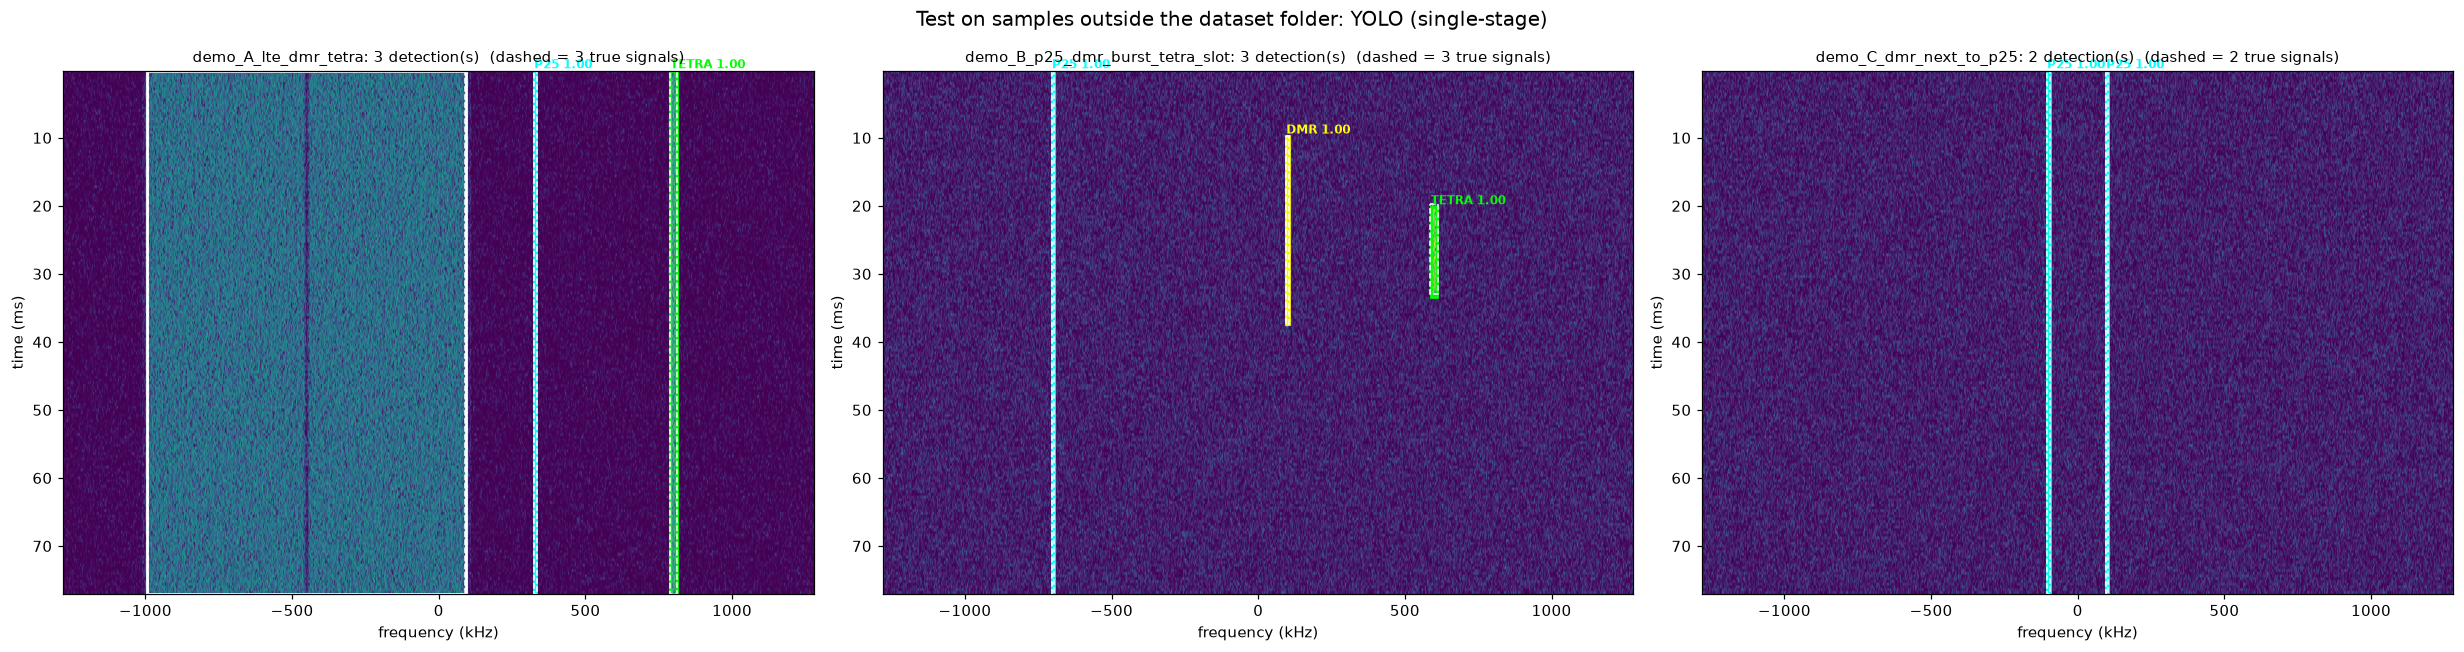

Predictions


,sample,family,class_confidence,detection_score,center_kHz,bandwidth_kHz,start_ms,end_ms
0,demo_A_lte_dmr_tetra,LTE,1.0,0.986,-448.750,1087.50,0.2,77.0
1,demo_A_lte_dmr_tetra,TETRA,1.0,0.895,800.625,21.25,0.2,77.0
2,demo_A_lte_dmr_tetra,P25,1.0,0.748,330.000,7.50,0.2,77.0
3,demo_B_p25_dmr_burst_tetra_slot,TETRA,1.0,0.827,600.000,22.50,20.2,33.4
4,demo_B_p25_dmr_burst_tetra_slot,P25,1.0,0.782,-698.750,7.50,0.2,77.0
5,demo_B_p25_dmr_burst_tetra_slot,DMR,1.0,0.719,101.250,10.00,9.8,37.4
6,demo_C_dmr_next_to_p25,P25,1.0,0.786,-99.375,8.75,0.2,77.0
7,demo_C_dmr_next_to_p25,P25,1.0,0.781,101.250,7.50,0.2,77.0


Comparison with the ground truth of the demo samples


,sample,true_class,true_family,snr_db,detected,predicted_family,family_correct
0,demo_A_lte_dmr_tetra,LTE,LTE,15.0,True,LTE,True
1,demo_A_lte_dmr_tetra,DMR,DMR,24.0,True,P25,False
2,demo_A_lte_dmr_tetra,TETRA,TETRA,22.0,True,TETRA,True
3,demo_A_lte_dmr_tetra,(false alarms),NaN,NaN,0,NaN,NaN
4,demo_B_p25_dmr_burst_tetra_slot,P25,P25,24.0,True,P25,True
5,demo_B_p25_dmr_burst_tetra_slot,DMR,DMR,26.0,True,DMR,True
6,demo_B_p25_dmr_burst_tetra_slot,TETRA,TETRA,24.0,True,TETRA,True
7,demo_B_p25_dmr_burst_tetra_slot,(false alarms),NaN,NaN,0,NaN,NaN
8,demo_C_dmr_next_to_p25,DMR,DMR,26.0,True,P25,False
9,demo_C_dmr_next_to_p25,P25,P25,26.0,True,P25,True


detected 8 of 8 signals, family correct for 6 of 8


In [16]:
BEST_DET, BEST_CLF = PIPELINES[BEST]
print(f"best algorithm: {BEST}   (detector: {BEST_DET}, classifier: {BEST_CLF or 'the detector itself'})")


def predict_sample(sample):
    dets = DETECTORS[BEST_DET].detect(sample["db"])
    return apply_pipeline(sample["db"], sample["iq"], BEST, dets)


def box_to_axes(b):                          # same geometry as plot_scene in 01_create_dataset.ipynb
    return ((b[0] - N_FFT / 2 - 0.5) * DF / 1e3, (b[2] - N_FFT / 2 + 0.5) * DF / 1e3,
            (b[1] * HOP + N_FFT / 2 - HOP / 2) / FS * 1e3, (b[3] * HOP + N_FFT / 2 + HOP / 2) / FS * 1e3)


def gt_to_box(t):                            # ground truth (centre, bandwidth, on-time) -> pixel box
    x0 = int(np.clip(round((t["center_hz"] - t["bw_hz"] / 2) / DF + N_FFT / 2), 0, N_FFT - 1))
    x1 = int(np.clip(round((t["center_hz"] + t["bw_hz"] / 2) / DF + N_FFT / 2), x0, N_FFT - 1))
    y0 = int(np.clip(np.ceil((t["t0_ms"] * FS / 1e3 - N_FFT / 2) / HOP), 0, N_FRAMES - 2))
    y1 = int(np.clip(np.floor((t["t1_ms"] * FS / 1e3 - 1 - N_FFT / 2) / HOP), y0 + 1, N_FRAMES - 1))
    return (x0, y0, x1, y1)


EXTENT = [(-N_FFT / 2 - 0.5) * DF / 1e3, (N_FFT / 2 - 0.5) * DF / 1e3,
          ((N_FRAMES - 1) * HOP + N_FFT / 2 + HOP / 2) / FS * 1e3, (N_FFT / 2 - HOP / 2) / FS * 1e3]

report_rows = []
fig, axes = plt.subplots(1, len(SAMPLES), figsize=(7.5 * len(SAMPLES), 6), squeeze=False)
for ax, s in zip(axes[0], SAMPLES):
    preds = predict_sample(s)
    ax.imshow(s["db"], aspect="auto", extent=EXTENT, cmap="viridis", vmin=-5, vmax=30)
    ax.grid(False)
    for p in preds:
        f0, f1, t0, t1 = box_to_axes(p["box"])
        c = FAM_COLOR[p["family"]]
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec=c, lw=1.8))
        ax.text(f0, t0, f'{FAMILIES[p["family"]]} {p["prob"]:.2f}', color=c, fontsize=8, va="bottom", fontweight="bold")
        report_rows.append(dict(sample=s["name"], family=FAMILIES[p["family"]], class_confidence=p["prob"], detection_score=p["score"],
                                center_kHz=box_center_hz(p["box"]) / 1e3, bandwidth_kHz=(p["box"][2] - p["box"][0] + 1) * DF / 1e3,
                                start_ms=box_times_ms(p["box"])[0], end_ms=box_times_ms(p["box"])[1]))
    title = f'{s["name"]}: {len(preds)} detection(s)'
    if s["gt"]:                                                      # dashed white = ground truth of the demo samples
        for t in s["gt"]:
            f0, f1, t0, t1 = box_to_axes(gt_to_box(t))
            ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec="white", lw=1.0, ls="--"))
        title += f'  (dashed = {len(s["gt"])} true signals)'
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("frequency (kHz)")
    ax.set_ylabel("time (ms)")
fig.suptitle(f"Test on samples outside the dataset folder: {BEST}", fontsize=13)
plt.tight_layout()
plt.show()

print("Predictions")
display(pd.DataFrame(report_rows))

# compare with the ground truth where it is known (the generated demo samples)
cmp_rows = []
for s in SAMPLES:
    if not s["gt"]:
        continue
    preds = predict_sample(s)
    gtb = [gt_to_box(t) for t in s["gt"]]
    m = match_detections([p["box"] for p in preds], [p["score"] for p in preds], gtb, thr=0.3)     # IoU 0.3: the truth boxes are approximate
    found = {int(g): p for p, g in enumerate(m) if g >= 0}
    for g, t in enumerate(s["gt"]):
        p = preds[found[g]] if g in found else None
        cmp_rows.append(dict(sample=s["name"], true_class=t["kind"], true_family=t["family"], snr_db=t["snr_db"], detected=p is not None,
                             predicted_family=FAMILIES[p["family"]] if p else "-", family_correct=bool(p and FAMILIES[p["family"]] == t["family"])))
    cmp_rows.append(dict(sample=s["name"], true_class="(false alarms)", detected=int((m < 0).sum())))
if cmp_rows:
    cmp = pd.DataFrame(cmp_rows)
    print("Comparison with the ground truth of the demo samples")
    display(cmp)
    sig = cmp[cmp.true_class != "(false alarms)"]
    print(f"detected {int(sig.detected.sum())} of {len(sig)} signals, family correct for {int(sig.family_correct.sum())} of {len(sig)}")
